# BillPay — Stage 2 Categorizer: Data Synthesis & Training

CCDS26-0127 · Anshika Uppal · Supervisor: Dr Gu Chloe

This notebook replaces the earlier hand-invented data synthesis (fixed adjacent-letter swap, always-first-word abbreviation) with methods grounded in published research, per Dr Gu's feedback on the Project Plan:

| Literature | What it grounds |
|---|---|
| Damerau (1964), *A Technique for Computer Detection and Correction of Spelling Errors* | Real typos are ~80%+ one of 4 error types: substitution, deletion, insertion, transposition — sampled randomly here instead of always doing the same edit |
| Kukich (1992), *Techniques for Automatically Correcting Words in Text* | Confirms the same single-error taxonomy is the standard basis for text-correction/noise systems |
| Belinkov & Bisk (2018), *Synthetic and Natural Noise Both Break Neural Machine Translation* | Keyboard-adjacent (QWERTY) substitution is more realistic noise than a random character swap |
| Company entity-matching / legal-form classification research | Real-world abbreviation patterns: first-token, initials, or prefix-cut — sampled randomly here instead of a single fixed rule |
| Leipzig entity-resolution benchmark practice | Corruption applied at a controlled, randomized rate, with independent repeated draws rather than one fixed variant per record |

The registry (biller name -> category) is read from `billpay_backend/ml/biller_registry.json`, the single source of truth shared with the production categorizer's Stage 1 rules — this notebook only changes *how the surface-form variants are generated*, so category names stay aligned with the production categorizer.


In [1]:
import random
import csv
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
!pip install -q scikit-learn==1.8.0
random.seed(42)
np.random.seed(42)


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Biller registry

Loaded from `biller_registry.json` (the same file `billpay_backend/ml/categorizer.py` uses for Stage 1), so Stage 1 rules and Stage 2 training always use the same billers and category names. To add a biller, edit that JSON, not this notebook.

On Colab: when prompted, upload `billpay_backend/ml/biller_registry.json`. Locally: it is found automatically.

In [2]:
import json, os

_candidates = ["biller_registry.json", "../billpay_backend/ml/biller_registry.json"]
REGISTRY_PATH = next((p for p in _candidates if os.path.exists(p)), None)

if REGISTRY_PATH is None:  # e.g. Colab: ask for the file
    from google.colab import files
    print("Upload billpay_backend/ml/biller_registry.json")
    files.upload()
    REGISTRY_PATH = "biller_registry.json"

with open(REGISTRY_PATH, encoding="utf-8") as f:
    BILLER_REGISTRY = json.load(f)

print(f"Loaded {REGISTRY_PATH}")
print(f"{len(BILLER_REGISTRY)} billers across {len(set(BILLER_REGISTRY.values()))} categories")


Loaded ../billpay_backend/ml/biller_registry.json
51 billers across 10 categories


## 2. Literature-grounded corruption functions

Replaces the old `typo()` (always swapped the same two adjacent letters) and `truncate()` (always took the first word) with randomized, research-grounded equivalents.

In [3]:
# QWERTY adjacency map — used for substitution errors (Belinkov & Bisk, 2018)
QWERTY_NEIGHBORS = {
    "q": "wa", "w": "qeas", "e": "wrsd", "r": "edft", "t": "rfgy", "y": "tghu",
    "u": "yhji", "i": "ujko", "o": "iklp", "p": "ol",
    "a": "qwsz", "s": "awedxz", "d": "serfcx", "f": "drtgvc", "g": "ftyhbv",
    "h": "gyujnb", "j": "huikmn", "k": "jiolm", "l": "kop",
    "z": "asx", "x": "zsdc", "c": "xdfv", "v": "cfgb", "b": "vghn", "n": "bhjm", "m": "njk",
}


def qwerty_neighbor(ch: str) -> str:
    """Return a random QWERTY-adjacent key for ch, preserving case (Belinkov & Bisk, 2018)."""
    lower = ch.lower()
    neighbors = QWERTY_NEIGHBORS.get(lower)
    if not neighbors:
        return ch
    repl = random.choice(neighbors)
    return repl.upper() if ch.isupper() else repl


def single_edit_error(name: str) -> str:
    """
    One randomly-chosen single-edit error: substitution, deletion, insertion,
    or transposition — the four error types Damerau (1964) found account for
    80%+ of real human typos (taxonomy confirmed by Kukich, 1992).
    Substitutions use a QWERTY-adjacent key (Belinkov & Bisk, 2018) rather
    than a uniformly random letter.
    """
    if len(name) < 4:
        return name
    error_type = random.choice(["substitution", "deletion", "insertion", "transposition"])
    chars = list(name)
    pos = random.randint(1, len(chars) - 2)  # avoid first/last char

    if error_type == "substitution":
        chars[pos] = qwerty_neighbor(chars[pos])
    elif error_type == "deletion":
        del chars[pos]
    elif error_type == "insertion":
        chars.insert(pos, qwerty_neighbor(chars[pos]))
    elif error_type == "transposition" and pos < len(chars) - 1:
        chars[pos], chars[pos + 1] = chars[pos + 1], chars[pos]

    return "".join(chars)


def abbreviate(name: str) -> str:
    """
    Randomly chosen abbreviation strategy — first-token, initials, or
    prefix-cut — reflecting documented real-world patterns from company
    entity-matching / legal-form classification research, rather than
    always applying one fixed rule.
    """
    words = name.split()
    if len(words) == 1:
        cut = max(3, len(name) - 2)
        return name[:cut].upper()

    strategy = random.choice(["first_token", "initials", "prefix_cut"])
    if strategy == "first_token":
        return words[0].upper()
    elif strategy == "initials":
        return "".join(w[0].upper() for w in words)
    else:  # prefix_cut
        cut = max(3, len(name) - 2)
        return name[:cut].upper()


LEGAL_SUFFIXES = [" Pte Ltd", " Ltd", " Limited", " Group"]


def legal_suffix(name: str) -> str:
    return name + random.choice(LEGAL_SUFFIXES)


def statement_format(name: str) -> str:
    compact = name.upper().replace(" ", "-")
    return f"{compact[:14]}-SG"


# quick sanity check
for demo in ["Singtel", "SP Power", "NTU Fees"]:
    print(f"{demo!r:20} -> typo1={single_edit_error(demo)!r:20} typo2={single_edit_error(demo)!r:20} abbr={abbreviate(demo)!r}")

'Singtel'            -> typo1='Skngtel'            typo2='Sigtel'             abbr='SINGT'
'SP Power'           -> typo1='SP Powr'            typo2='SP Powwr'           abbr='SP POW'
'NTU Fees'           -> typo1='NUT Fees'           typo2='NFU Fees'           abbr='NTU'


## 3. Build the training dataset

Each registry biller is expanded into: the original name, a case variant, a legal-suffix variant, an abbreviation, a statement-format variant, and **two independently-drawn** typo variants (per Leipzig benchmark practice — the same name shouldn't corrupt the same way every time).

In [4]:
rows = []
for name, category in BILLER_REGISTRY.items():
    rows.append([name, category, name, "original (registry)"])
    rows.append([name.upper(), category, name, "case variant"])
    rows.append([legal_suffix(name), category, name, "legal-suffix"])
    rows.append([abbreviate(name), category, name, "abbreviation"])
    rows.append([statement_format(name), category, name, "statement-format"])
    rows.append([single_edit_error(name), category, name, "typo-1"])
    rows.append([single_edit_error(name), category, name, "typo-2"])

random.shuffle(rows)

df = pd.DataFrame(rows, columns=["biller_name", "category", "source_biller", "variant_type"])
df.to_csv("biller_training_data.csv", index=False)

print(f"Wrote {len(df)} rows across {len(BILLER_REGISTRY)} base billers -> biller_training_data.csv\n")
print(df["category"].value_counts().sort_index())

Wrote 357 rows across 51 base billers -> biller_training_data.csv

category
Education        35
Entertainment    42
Finance          49
Food & Dining    14
Housing          28
Insurance        42
Telecoms         42
Transport        28
Travel           28
Utilities        49
Name: count, dtype: int64


In [5]:
df.sample(10, random_state=1)

,biller_name,category,source_biller,variant_type
273,GREAT-EASTERN-SG,Insurance,Great Eastern,statement-format
234,City Gas Group,Utilities,City Gas,legal-suffix
333,DBS Home Loan,Finance,DBS Home Loan,original (registry)
165,SIT-FEES-SG,Education,SIT Fees,statement-format
321,APPLE-TV-SG,Entertainment,Apple TV,statement-format
303,STARH,Telecoms,StarHub,abbreviation
211,Marina Ba ySands,Travel,Marina Bay Sands,typo-1
65,AIA,Insurance,AIA Insurance,abbreviation
251,Sintel,Telecoms,Singtel,typo-1
287,CITY GAS,Utilities,City Gas,case variant


## 4. Train: TF-IDF (character n-grams) + Logistic Regression

Matches the Stage 2 pipeline described in the Project Plan (Section 6).

In [6]:
names = df["biller_name"].tolist()
labels = df["category"].tolist()

X_train, X_test, y_train, y_test = train_test_split(
    names, labels, test_size=0.2, stratify=labels, random_state=42
)

vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))
clf = LogisticRegression(max_iter=1000, C=5.0, random_state=42)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

clf.fit(X_train_vec, y_train)
y_pred = clf.predict(X_test_vec)

print("=== Held-out test accuracy ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

=== Held-out test accuracy ===
Accuracy: 1.000

               precision    recall  f1-score   support

    Education       1.00      1.00      1.00         7
Entertainment       1.00      1.00      1.00         8
      Finance       1.00      1.00      1.00        10
Food & Dining       1.00      1.00      1.00         3
      Housing       1.00      1.00      1.00         6
    Insurance       1.00      1.00      1.00         8
     Telecoms       1.00      1.00      1.00         8
    Transport       1.00      1.00      1.00         6
       Travel       1.00      1.00      1.00         6
    Utilities       1.00      1.00      1.00        10

     accuracy                           1.00        72
    macro avg       1.00      1.00      1.00        72
 weighted avg       1.00      1.00      1.00        72



## 5. 5-fold cross-validation + confusion matrix

Matches the evaluation plan in the Project Plan / Dr Gu's 5th question ("how does the experiment perform with your data").

=== 5-fold cross-validation ===
CV Accuracy: 0.989

               precision    recall  f1-score   support

    Education       1.00      1.00      1.00        35
Entertainment       0.95      0.98      0.96        42
      Finance       1.00      0.98      0.99        49
Food & Dining       1.00      1.00      1.00        14
      Housing       1.00      0.96      0.98        28
    Insurance       1.00      0.98      0.99        42
     Telecoms       1.00      1.00      1.00        42
    Transport       1.00      1.00      1.00        28
       Travel       1.00      1.00      1.00        28
    Utilities       0.96      1.00      0.98        49

     accuracy                           0.99       357
    macro avg       0.99      0.99      0.99       357
 weighted avg       0.99      0.99      0.99       357



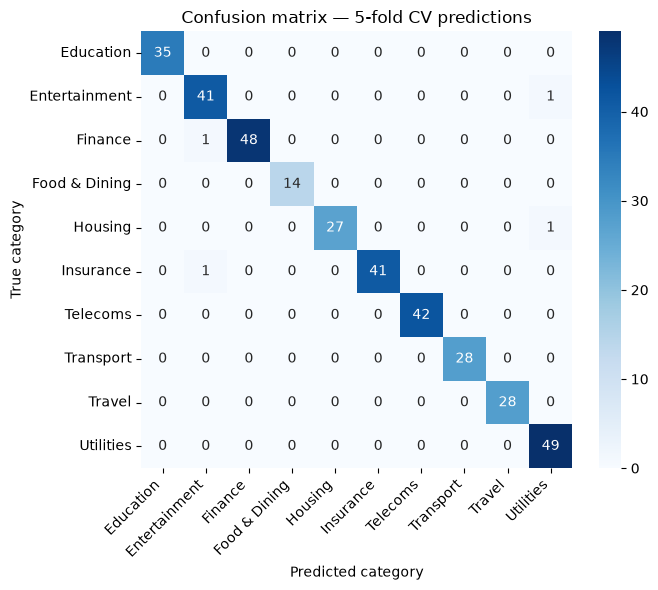

In [7]:
vectorizer_full = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))
X_all_vec = vectorizer_full.fit_transform(names)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_pred = cross_val_predict(clf, X_all_vec, labels, cv=skf)

print("=== 5-fold cross-validation ===")
print(f"CV Accuracy: {accuracy_score(labels, cv_pred):.3f}\n")
print(classification_report(labels, cv_pred, zero_division=0))

cats = sorted(set(labels))
cm = confusion_matrix(labels, cv_pred, labels=cats)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=cats, yticklabels=cats)
plt.xlabel("Predicted category")
plt.ylabel("True category")
plt.title("Confusion matrix — 5-fold CV predictions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

## 6. Save the trained pipeline

Saved as a single `Pipeline` object (vectorizer + classifier combined) so `billpay_backend/ml/categorizer.py` can load and call it with a single `model.predict([name])` / `model.predict_proba([name])`, matching how it already calls its inline-trained model.

In [8]:
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))),
    ("clf", LogisticRegression(max_iter=1000, C=5.0, random_state=42)),
])
final_pipeline.fit(names, labels)

joblib.dump(final_pipeline, "categorizer_stage2.joblib")
print("Saved trained pipeline -> categorizer_stage2.joblib")
print("\nSanity check on unseen-style inputs:")
for test_name in ["SP Power Pte Ltd", "Netlfix", "SINGTEL-SG", "Unknown Merchant XYZ"]:
    pred = final_pipeline.predict([test_name])[0]
    conf = final_pipeline.predict_proba([test_name]).max()
    print(f"  {test_name:25} -> {pred:15} ({conf:.0%} confidence)")

Saved trained pipeline -> categorizer_stage2.joblib

Sanity check on unseen-style inputs:
  SP Power Pte Ltd          -> Utilities       (89% confidence)
  Netlfix                   -> Entertainment   (59% confidence)
  SINGTEL-SG                -> Telecoms        (81% confidence)
  Unknown Merchant XYZ      -> Finance         (34% confidence)


In [9]:
   import sklearn; print(sklearn.__version__)

1.8.0


## 7. Next step — wiring into the app (not done in this notebook)

This notebook only produces `biller_training_data.csv`, `confusion_matrix.png`, and `categorizer_stage2.joblib`. To actually make the running app use this model:

1. Copy `categorizer_stage2.joblib` into `billpay_backend/ml/`.
2. In `billpay_backend/ml/categorizer.py`, point `get_model()` at `categorizer_stage2.joblib` instead of the inline-trained `ml/categorizer.pkl`.
3. Delete the old `ml/categorizer.pkl` so it doesn't keep getting loaded.
4. Restart `uvicorn` and check `GET /categorize/evaluate`.
